# Supplementary studies

These studies provide evidence about the chosen method. They do not change the submitted target weights. **Restart and Run All** from this notebook's `round-1` folder. All calculations are visible here; the main notebook need not be run first.

We retain the 108-specification constraint sensitivity study, source comparison, two historically frozen-weight checks, transaction-cost checks and the block-bootstrap uncertainty calculation. No historical period was untouched during research and no new rule is selected using these results. `Studies/research_variations.csv` records earlier overlapping trials; its counts are not independent tests or a complete count of every teammate's work.

In [1]:
from pathlib import Path
from itertools import product
from decimal import Decimal
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.stats import norm
from openpyxl import load_workbook
from IPython.display import display, Markdown

# Open this notebook from the round-1 folder; all input paths are relative to it.
ROOT = Path.cwd()
DATA = ROOT / "Data"
RESULTS = ROOT / "Results"
STUDIES = ROOT / "Studies"
RESULTS.mkdir(exist_ok=True)
STUDIES.mkdir(exist_ok=True)

CAPITAL = 100_000_000
TARGET_VOLATILITY = 0.08
TRADING_COST = 0.001
ASSETS = ["SPY", "VWO", "EEMV", "DBC", "SCHD", "VGSH", "STIP"]
FIT_START = "2021-10"
FIT_END = "2026-09"
BACKTEST_START = "2016-11"
POLICY = {
    "risk_cap": 0.40,
    "capital_cap": 0.35,
    "equity_risk_cap": 0.65,
    "building_block_floor": 0.05,
    "bond_floor": 0.20,
}
GROUPS = {
    "US": ["SPY", "SCHD"],
    "EM": ["VWO", "EEMV"],
    "commodities": ["DBC"],
    "VGSH": ["VGSH"],
    "STIP": ["STIP"],
}
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})

In [2]:
source_file = DATA / "bloomberg_prices.xlsx"
workbook = load_workbook(source_file, read_only=True, data_only=True)
rows = list(workbook.worksheets[0].values)
workbook.close()
assert list(rows[0][1:8]) == [ticker + " US Equity" for ticker in ASSETS]

source_dates = [row[0] for row in rows[1:]]
# The first cell's saved value is #NAME?; 31 October 2011 was confirmed by Kyla.
if source_dates[0] == "#NAME?":
    source_dates[0] = pd.Timestamp("2011-10-31")
source_dates = pd.DatetimeIndex(source_dates)
assert list(source_dates.to_period("M")) == list(pd.period_range("2011-10", "2026-09", freq="M"))

prices = pd.DataFrame([row[1:8] for row in rows[1:]], index=source_dates, columns=ASSETS).astype(float)
assert np.isfinite(prices.to_numpy()).all() and (prices > 0).all().all()
# Calendar month-end labels align ETF observations with the risk-free series.
# This changes the labels, not the observed prices, and fills no missing values.
prices.index = prices.index.to_period("M").to_timestamp("M")
prices.index.name = "month"
returns = prices.pct_change(fill_method=None).iloc[1:]
training = returns.loc[FIT_START:FIT_END]
assert len(prices) == 180 and len(returns) == 179 and len(training) == 60
assert returns.notna().all().all()
annual_covariance = training.cov() * 12
annual_mean = training.mean() * 12
annual_inputs = pd.DataFrame({
    "annual_mean_input": annual_mean,
    "annual_volatility": training.std(ddof=1) * np.sqrt(12),
})

In [3]:
def portfolio_volatility(weights, covariance):
    return float(np.sqrt(weights @ covariance @ weights))


def risk_shares(weights, covariance):
    variance = weights @ covariance @ weights
    return weights * (covariance @ weights) / variance


def risk_share_gradient(weights, covariance):
    # Analytic derivatives help SLSQP handle the nonlinear risk-share limits.
    marginal_covariance = covariance @ weights
    variance = weights @ marginal_covariance
    numerator_gradient = np.diag(marginal_covariance) + np.diag(weights) @ covariance
    variance_gradient = 2 * marginal_covariance
    return (numerator_gradient / variance
            - np.outer(weights * marginal_covariance, variance_gradient) / variance**2)


def policy_margins(weights, covariance, assets, policy):
    # Nonnegative margins mean the inequalities are satisfied.
    contributions = risk_shares(weights, covariance)
    equity_mask = np.array([ticker in {"SPY", "VWO", "EEMV", "SCHD"} for ticker in assets])
    margins = {
        "long_only": float(np.min(weights)),
        "capital_cap": float(policy["capital_cap"] - np.max(weights)),
        "risk_cap": float(policy["risk_cap"] - np.max(contributions)),
        "equity_risk_cap": float(policy["equity_risk_cap"] - contributions[equity_mask].sum()),
        "bond_floor": float(sum(weights[i] for i, ticker in enumerate(assets)
                                if ticker in {"VGSH", "STIP"}) - policy["bond_floor"]),
    }
    for group, tickers in GROUPS.items():
        exposure = sum(weights[i] for i, ticker in enumerate(assets) if ticker in tickers)
        floor = policy.get("floor_" + group, policy["building_block_floor"])
        margins[group + "_floor"] = float(exposure - floor)
    return pd.Series(margins)

In [4]:
def optimize_weights(sample, policy, target=TARGET_VOLATILITY,
                     seeds=(12, 91), random_starts=100, warm_starts=()):
    assets = list(sample.columns)
    count = len(assets)
    covariance = sample.cov().to_numpy() * 12
    means = sample.mean().to_numpy() * 12
    equity_mask = np.array([ticker in {"SPY", "VWO", "EEMV", "SCHD"} for ticker in assets], dtype=float)

    constraints = [
        {"type": "eq", "fun": lambda w: w.sum() - 1,
         "jac": lambda w: np.ones(count)},
        {"type": "eq", "fun": lambda w: (w @ covariance @ w) / target**2 - 1,
         "jac": lambda w: 2 * covariance @ w / target**2},
        {"type": "ineq", "fun": lambda w: policy["risk_cap"] - risk_shares(w, covariance),
         "jac": lambda w: -risk_share_gradient(w, covariance)},
        {"type": "ineq", "fun": lambda w: policy["equity_risk_cap"] - equity_mask @ risk_shares(w, covariance),
         "jac": lambda w: -equity_mask @ risk_share_gradient(w, covariance)},
    ]
    for group, tickers in {**GROUPS, "bonds": ["VGSH", "STIP"]}.items():
        mask = np.array([ticker in tickers for ticker in assets], dtype=float)
        floor = (policy["bond_floor"] if group == "bonds"
                 else policy.get("floor_" + group, policy["building_block_floor"]))
        # Capture each group's mask and floor separately in these functions.
        constraints.append({"type": "ineq", "fun": lambda w, m=mask, f=floor: m @ w - f,
                            "jac": lambda w, m=mask: m})

    solutions = []
    diagnostics = []
    for seed in seeds:
        generator = np.random.default_rng(seed)
        starts = list(warm_starts) + list(generator.dirichlet(np.ones(count), random_starts))
        valid = []
        for initial_weights in starts:
            solution = minimize(
                fun=lambda w: -means @ w, x0=initial_weights, jac=lambda w: -means,
                bounds=[(0, policy["capital_cap"])] * count,
                constraints=constraints, method="SLSQP",
                options={"ftol": 1e-11, "maxiter": 500},
            )
            candidate = solution.x
            feasible = (abs(candidate.sum() - 1) < 1e-7
                        and abs(portfolio_volatility(candidate, covariance) - target) < 1e-7
                        and policy_margins(candidate, covariance, assets, policy).min() >= -1e-7)
            if solution.success and feasible:
                valid.append(solution)
        diagnostics.append({"seed": seed, "starts": len(starts), "verified_solutions": len(valid),
                            "best_mean_return": -min(s.fun for s in valid) if valid else np.nan})
        solutions.extend(valid)
    if not solutions:
        raise RuntimeError("No verified feasible allocation found; do not substitute arbitrary weights.")
    best = min(solutions, key=lambda solution: solution.fun)
    return best.x, pd.DataFrame(diagnostics)

## 1. Constraint sensitivity

Hold Bloomberg inputs, eligible ETFs, objective and the 8% estimated-volatility target constant. Change one policy limit at a time, then combinations. Compare **unrounded** optima so rounding does not obscure sensitivity.

There are 108 distinct specifications: one baseline, 17 changes to a common limit, ten individual building-block floor changes, and 80 joint changes. Each specification has 48 starts across two seeds: the baseline allocation, equal weights and 22 random starts per seed. This is numerical sensitivity, not proof that the chosen thresholds are statistically optimal.

Capital reassigned is $\frac12\sum_i|w_i-w_i^{baseline}|$. We also record the largest individual weight change. We independently check covariance-based risk against the variance of the actual monthly portfolio returns.

In [5]:
baseline_weights, baseline_diagnostics = optimize_weights(training, POLICY)
specifications = [("Baseline", "baseline", POLICY.copy())]
def add_specification(label, kind, **changes):
    specifications.append((label, kind, POLICY | changes))

variations = {
    "risk_cap": [0.35, 0.375, 0.425, 0.45],
    "building_block_floor": [0.025, 0.075],
    "bond_floor": [0.15, 0.25, 0.30],
    "capital_cap": [0.30, 0.325, 0.375, 0.40],
    "equity_risk_cap": [0.55, 0.60, 0.70, 0.75],
}
for parameter, limits in variations.items():
    for limit in limits:
        add_specification(f"{parameter}={limit:.3f}", "one_limit", **{parameter: limit})
for group in GROUPS:
    for limit in [0.025, 0.075]:
        add_specification(f"{group} minimum={limit:.3f}", "individual_floor", **{"floor_" + group: limit})
for risk_cap, floor, capital_cap, equity_cap in product(
    [0.35, 0.40, 0.45], [0.025, 0.05, 0.075], [0.30, 0.35, 0.40], [0.60, 0.65, 0.70]
):
    candidate_policy = POLICY | {"risk_cap": risk_cap, "building_block_floor": floor,
                                "capital_cap": capital_cap, "equity_risk_cap": equity_cap}
    if candidate_policy != POLICY:
        specifications.append((f"Joint {len(specifications)}", "joint", candidate_policy))
assert len(specifications) == 108

In [6]:
covariance = annual_covariance.to_numpy()
sensitivity_rows = []
sensitivity_weights = {}
for number, (label, kind, policy) in enumerate(specifications):
    weights, diagnostics = optimize_weights(
        training, policy, seeds=(17, 83), random_starts=22,
        warm_starts=(baseline_weights, np.ones(len(ASSETS)) / len(ASSETS)),
    )
    direct_returns = training.to_numpy() @ weights
    direct_variance = np.var(direct_returns, ddof=1) * 12
    direct_risk = np.array([
        weights[i] * np.cov(training.iloc[:, i], direct_returns, ddof=1)[0, 1] * 12 / direct_variance
        for i in range(len(ASSETS))
    ])
    assert np.max(abs(direct_risk - risk_shares(weights, covariance))) < 1e-10
    assert abs(np.sqrt(direct_variance) - TARGET_VOLATILITY) < 1e-7
    assert policy_margins(weights, covariance, ASSETS, policy).min() >= -1e-7
    seed_gap = diagnostics["best_mean_return"].max() - diagnostics["best_mean_return"].min()
    assert diagnostics["best_mean_return"].notna().all() and seed_gap < 1e-9
    row = {"scenario": label, "kind": kind, **policy,
           **dict(zip(ASSETS, weights)),
           "max_weight_change_pp": float(np.max(abs(weights - baseline_weights)) * 100),
           "capital_reassigned_pct": float(np.abs(weights - baseline_weights).sum() / 2 * 100),
           "estimated_mean": float(annual_mean.to_numpy() @ weights),
           "estimated_volatility": float(np.sqrt(direct_variance)),
           "seed_objective_gap": float(seed_gap),
           "verified_solutions": int(diagnostics["verified_solutions"].sum())}
    row.update({ticker + "_risk": float(direct_risk[i]) for i, ticker in enumerate(ASSETS)})
    sensitivity_rows.append(row)
    sensitivity_weights[label] = weights
sensitivity = pd.DataFrame(sensitivity_rows).set_index("scenario")
sensitivity.to_csv(STUDIES / "constraint_sensitivity.csv")
display(sensitivity.loc[sensitivity["kind"] != "joint", ASSETS + ["capital_reassigned_pct"]]
        .style.format({**{a: "{:.2%}" for a in ASSETS}, "capital_reassigned_pct": "{:.2f}"}))

,SPY,VWO,EEMV,DBC,SCHD,VGSH,STIP,capital_reassigned_pct
scenario,,,,,,,,
Baseline,26.08%,0.00%,9.65%,26.96%,3.28%,5.00%,29.03%,0.00
risk_cap=0.350,22.57%,0.00%,12.17%,24.56%,7.87%,5.00%,27.84%,7.10
risk_cap=0.375,24.30%,0.00%,10.95%,25.77%,5.61%,5.00%,28.36%,3.64
risk_cap=0.425,27.92%,0.00%,8.27%,28.13%,0.83%,5.00%,29.85%,3.83
risk_cap=0.450,29.83%,0.00%,5.00%,29.19%,0.00%,10.77%,25.20%,11.76
building_block_floor=0.025,26.10%,0.00%,9.60%,26.93%,3.03%,2.50%,31.84%,2.82
building_block_floor=0.075,26.07%,0.00%,9.70%,26.98%,3.52%,7.50%,26.22%,2.82
bond_floor=0.150,26.08%,0.00%,9.65%,26.96%,3.28%,5.00%,29.03%,0.00
bond_floor=0.250,26.08%,0.00%,9.65%,26.96%,3.28%,5.00%,29.03%,0.00


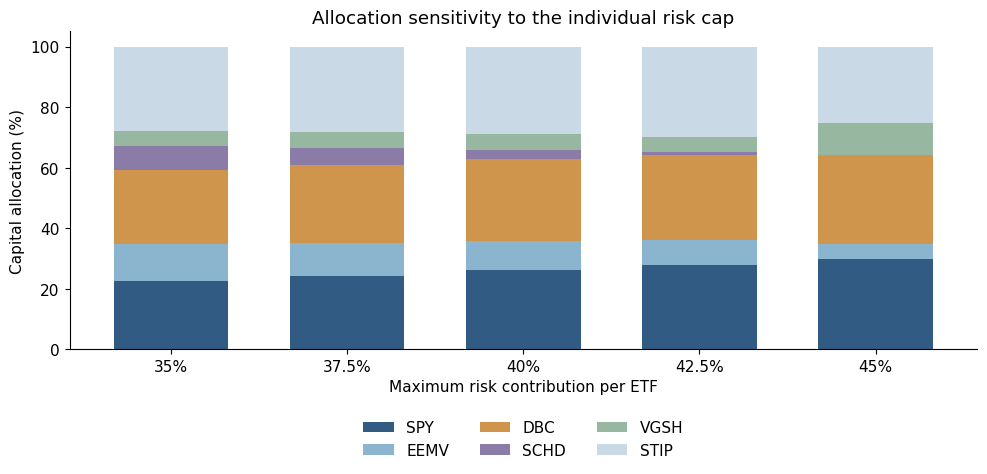

In [7]:
selected = ["risk_cap=0.350", "risk_cap=0.375", "Baseline", "risk_cap=0.425", "risk_cap=0.450"]
visible_assets = [ticker for ticker in ["SPY", "EEMV", "DBC", "SCHD", "VGSH", "STIP"]
                  if sensitivity.loc[selected, ticker].max() > 1e-8]
chart = sensitivity.loc[selected, visible_assets].copy()
chart.index = ["35%", "37.5%", "40%", "42.5%", "45%"]
figure, axis = plt.subplots()
(chart * 100).plot.bar(stacked=True, ax=axis, width=0.65, rot=0,
                     color=["#315b83", "#8bb5cf", "#cf954d", "#8a7ba7", "#98b7a1", "#c9d9e6"])
axis.set(title="Allocation sensitivity to the individual risk cap",
         xlabel="Maximum risk contribution per ETF", ylabel="Capital allocation (%)")
axis.legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18))
figure.tight_layout()
figure.savefig(STUDIES / "risk_cap_allocations.png", dpi=170, bbox_inches="tight")
plt.show()

### What this can justify

The risk cap and VGSH minimum materially shape the allocation. Other limits can remain useful safeguards even when they do not bind today. Small isolated changes and wider combined changes must be distinguished. A solution disappearing or a large shift is a finding, not a reason to conceal a scenario. The study does not identify a unique optimal policy threshold, and we do not choose limits by maximizing historical Sharpe.

In [8]:
nearby = sensitivity.loc[["risk_cap=0.375", "risk_cap=0.425"], "capital_reassigned_pct"]
largest_joint = sensitivity.loc[sensitivity["kind"] == "joint", "capital_reassigned_pct"].max()
display(nearby.to_frame())
print(f"Largest tested joint capital reassignment: {largest_joint:.2f}%")

,capital_reassigned_pct
scenario,
risk_cap=0.375,3.635231
risk_cap=0.425,3.833256


Largest tested joint capital reassignment: 24.49%


## 2. Earlier Yahoo inputs versus Bloomberg

The old Yahoo prices remain as one ordinary CSV in `Data/`. This comparison documents the data-source change, not a second active data pipeline. The active optimization always uses Bloomberg. No archived result JSON is needed to run the analysis.

In [9]:
yahoo_prices = pd.read_csv(DATA / "yahoo_month_end_prices.csv", index_col=0, parse_dates=True)[ASSETS]
yahoo_returns = yahoo_prices.pct_change(fill_method=None).iloc[1:]
common_months = returns.index.intersection(yahoo_returns.index)
absolute_difference = (returns.loc[common_months] - yahoo_returns.loc[common_months]).abs()
source_comparison = pd.DataFrame({
    "mean_absolute_return_difference": absolute_difference.mean(),
    "max_absolute_return_difference": absolute_difference.max(),
    "largest_difference_month": absolute_difference.idxmax(),
})
source_comparison.to_csv(STUDIES / "source_comparison.csv")
display(source_comparison.style.format({"mean_absolute_return_difference": "{:.5%}",
                                        "max_absolute_return_difference": "{:.5%}"}))

,mean_absolute_return_difference,max_absolute_return_difference,largest_difference_month
SPY,0.00020%,0.00408%,2012-06-30 00:00:00
VWO,0.00124%,0.02543%,2013-10-31 00:00:00
EEMV,0.00035%,0.00894%,2022-07-31 00:00:00
DBC,0.00025%,0.00345%,2018-12-31 00:00:00
SCHD,0.00076%,0.01451%,2012-11-30 00:00:00
VGSH,0.00162%,0.05462%,2015-11-30 00:00:00
STIP,0.00164%,0.19009%,2012-11-30 00:00:00


In [10]:
treasury = pd.read_csv(DATA / "fred_dgs1mo.csv", parse_dates=["observation_date"])
treasury["DGS1MO"] = pd.to_numeric(treasury["DGS1MO"], errors="coerce")
treasury = treasury.dropna(subset=["DGS1MO"]).set_index("observation_date").sort_index()
risk_free_rows = []
for month in returns.index:
    first_day = month.replace(day=1)
    prior = treasury.loc[treasury.index < first_day, "DGS1MO"]
    if prior.empty:
        raise ValueError(f"No Treasury yield available before {first_day.date()}.")
    annual_yield_percent = float(prior.iloc[-1])
    monthly_proxy = annual_yield_percent / 100 * month.days_in_month / 365
    risk_free_rows.append([month, prior.index[-1], annual_yield_percent, monthly_proxy])
risk_free_table = pd.DataFrame(risk_free_rows, columns=[
    "month", "yield_observation_date", "annual_yield_percent", "monthly_rf_proxy"
]).set_index("month")
risk_free = risk_free_table["monthly_rf_proxy"]

In [11]:
def simulate_fixed_weights(weights, asset_returns, trading_cost=TRADING_COST):
    drifted_weights = np.zeros(len(weights))
    rows = []
    for month, observations in asset_returns.iterrows():
        traded_fraction = float(np.abs(weights - drifted_weights).sum())
        gross_return = float(weights @ observations.to_numpy())
        net_return = (1 - trading_cost * traded_fraction) * (1 + gross_return) - 1
        rows.append([month, gross_return, traded_fraction, net_return])
        drifted_weights = weights * (1 + observations.to_numpy()) / (1 + gross_return)
    return pd.DataFrame(rows, columns=["month", "gross_return", "traded_fraction", "net_return"]).set_index("month")


def performance_statistics(net_returns):
    observations = net_returns.to_numpy()
    # Include initial wealth so an immediate first-month loss counts as drawdown.
    wealth = np.cumprod(np.r_[1.0, 1 + observations])
    drawdown = wealth / np.maximum.accumulate(wealth) - 1
    volatility = observations.std(ddof=1) * np.sqrt(12)
    excess_returns = net_returns - risk_free.reindex(net_returns.index)
    assert excess_returns.notna().all()
    return pd.Series({
        "months": len(observations),
        "cagr": wealth[-1]**(12 / len(observations)) - 1,
        "volatility": volatility,
        "sharpe": excess_returns.mean() * 12 / volatility,
        "max_month_end_drawdown": drawdown.min(),
        "historical_monthly_95pct_var": -np.quantile(observations, 0.05, method="linear"),
        "terminal_value_usd": CAPITAL * wealth[-1],
    })

## 3. Historical performance of the constraint variants

Apply each variant's fixed weights over the same retrospective period and with the same trading-cost convention. These numbers are context only: neither model selection nor a holdout is created by this calculation. The sensitivity test uses exact weights; the main report uses implementable rounded target weights, so tiny baseline differences are expected.

In [12]:
study_evaluation = returns.loc[BACKTEST_START:, ASSETS]
sensitivity_performance = pd.DataFrame({
    label: performance_statistics(simulate_fixed_weights(weights, study_evaluation)["net_return"])
    for label, weights in sensitivity_weights.items()
}).T
sensitivity_performance.to_csv(STUDIES / "constraint_backtest_context.csv")
display(sensitivity_performance.loc[selected, ["cagr", "volatility", "sharpe", "max_month_end_drawdown"]]
        .style.format({"cagr": "{:.2%}", "volatility": "{:.2%}", "sharpe": "{:.3f}",
                       "max_month_end_drawdown": "{:.2%}"}))

,cagr,volatility,sharpe,max_month_end_drawdown
risk_cap=0.350,8.96%,8.61%,0.758,-16.26%
risk_cap=0.375,9.00%,8.61%,0.763,-16.24%
Baseline,9.04%,8.60%,0.768,-16.19%
risk_cap=0.425,9.07%,8.59%,0.772,-16.11%
risk_cap=0.450,9.13%,8.55%,0.782,-15.80%


## 4. Frozen historical fits

These reproduce the earlier supplementary tests. Fit on the 60 months before November 2016 or November 2021, then hold those targets fixed over the subsequent period and rebalance monthly. Training excludes the evaluation returns. The universe and rules were nevertheless selected retrospectively, so this is **conditional historical validation, not an untouched holdout**. These tests do not test today's exact allocation.

The original studies fit the same six selected holdings. Their predefined numerical fallback tries 8%, then 7.5%, then 7% estimated volatility only if no verified solution is found. The actual target and training dates are shown for each test.

In [13]:
def historical_parity(covariance):
    count = len(covariance)
    scaled = covariance / np.mean(np.diag(covariance))
    budgets = np.ones(count) / count
    solution = minimize(lambda x: 0.5 * x @ scaled @ x - budgets @ np.log(x),
                        np.ones(count), jac=lambda x: scaled @ x - budgets / x,
                        bounds=[(1e-10, None)] * count, method="L-BFGS-B",
                        options={"ftol": 1e-15, "gtol": 1e-10, "maxiter": 3000})
    weights = solution.x / solution.x.sum()
    assert np.max(abs(risk_shares(weights, covariance) - budgets)) < 1e-7
    return weights

historical_assets = ["SPY", "EEMV", "DBC", "VGSH", "SCHD", "STIP"]
historical_results = []
historical_weights = []
for first_test_month in ["2016-11-30", "2021-11-30"]:
    start = pd.Timestamp(first_test_month)
    sample = returns.loc[returns.index < start, historical_assets].tail(60)
    assert len(sample) == 60 and sample.index[-1] < start
    trained_weights = None
    for target in [0.08, 0.075, 0.07]:
        try:
            trained_weights, diagnostics = optimize_weights(sample, POLICY, target=target)
            break
        except RuntimeError:
            continue
    if trained_weights is None:
        raise RuntimeError("No verified historical fit in the volatility band.")
    sample_covariance = sample.cov().to_numpy() * 12
    alternatives = {"Trained MVO": trained_weights,
                    "Equal weight": np.ones(6) / 6,
                    "Trained risk parity": historical_parity(sample_covariance)}
    for name, weights in alternatives.items():
        net = simulate_fixed_weights(weights, returns.loc[start:, historical_assets])["net_return"]
        row = performance_statistics(net).to_dict()
        row.update(test_start=first_test_month, portfolio=name, fit_first=str(sample.index[0].date()),
                   fit_last=str(sample.index[-1].date()), selected_mvo_volatility_target=target)
        historical_results.append(row)
        historical_weights.append({"test_start": first_test_month, "portfolio": name,
                                   **dict(zip(historical_assets, weights))})
historical_summary = pd.DataFrame(historical_results)
historical_summary.to_csv(STUDIES / "historical_fit_summary.csv", index=False)
pd.DataFrame(historical_weights).to_csv(STUDIES / "historical_fit_weights.csv", index=False)
display(historical_summary[["test_start", "portfolio", "fit_first", "fit_last",
                            "selected_mvo_volatility_target", "cagr", "volatility", "sharpe"]])

,test_start,portfolio,fit_first,fit_last,selected_mvo_volatility_target,cagr,volatility,sharpe
0,2016-11-30,Trained MVO,2011-11-30,2016-10-31,0.08,0.106798,0.102416,0.806996
1,2016-11-30,Equal weight,2011-11-30,2016-10-31,0.08,0.084901,0.083002,0.731379
2,2016-11-30,Trained risk parity,2011-11-30,2016-10-31,0.08,0.029632,0.020556,0.240709
3,2021-11-30,Trained MVO,2016-11-30,2021-10-31,0.08,0.076015,0.071801,0.520116
4,2021-11-30,Equal weight,2016-11-30,2021-10-31,0.08,0.076675,0.077981,0.492606
5,2021-11-30,Trained risk parity,2016-11-30,2021-10-31,0.08,0.027407,0.024689,-0.458397


## 5. Transaction-cost and Sharpe uncertainty checks

Calculate the baseline rounded allocation here with the same adjacent-rounding rule, without reading outputs from the main notebook. Cost comparisons charge 0, 10 or 25 basis points per dollar traded. The bootstrap resamples paired portfolio and risk-free observations in circular six-month blocks, with 3,000 replications. It provides conditional sampling uncertainty, not a correction for selection bias or a guaranteed forward Sharpe.

In [14]:
exact_weights, solver_diagnostics = baseline_weights, baseline_diagnostics
covariance = annual_covariance.to_numpy()

def acceptable_rounding(weights):
    volatility = portfolio_volatility(weights, covariance)
    return (abs(weights.sum() - 1) < 1e-12
            and 0.07 <= volatility <= TARGET_VOLATILITY + 1e-10
            and policy_margins(weights, covariance, ASSETS, POLICY).min() >= -1e-10)

target_weights = np.round(exact_weights, 4)
target_weights[-1] = 1 - target_weights[:-1].sum()
if not acceptable_rounding(target_weights):
    # Try adjacent 0.01 percentage-point grid values, not a new portfolio search.
    lower_weights = np.floor(exact_weights * 10_000) / 10_000
    feasible_roundings = []
    for increments in product([0, 1], repeat=len(ASSETS)):
        candidate = lower_weights + np.array(increments) / 10_000
        if acceptable_rounding(candidate):
            feasible_roundings.append(candidate)
    if not feasible_roundings:
        raise RuntimeError("No nearby rounded allocation satisfies the policy limits.")
    target_weights = min(feasible_roundings, key=lambda w: np.sum((w - exact_weights)**2))

allocation = pd.DataFrame({
    "exact_weight": exact_weights,
    "target_weight": target_weights,
    "risk_share": risk_shares(target_weights, covariance),
    "target_value_usd": target_weights * CAPITAL,
}, index=ASSETS)
allocation.index.name = "ticker"
display(solver_diagnostics.style.format({"best_mean_return": "{:.4%}"}))
display(allocation.style.format({"exact_weight": "{:.6%}", "target_weight": "{:.2%}",
                                 "risk_share": "{:.2%}", "target_value_usd": "${:,.2f}"}))

,seed,starts,verified_solutions,best_mean_return
0,12,100,97,9.2806%
1,91,100,97,9.2806%


,exact_weight,target_weight,risk_share,target_value_usd
ticker,,,,
SPY,26.083326%,26.08%,40.00%,"$26,080,000.00"
VWO,0.000000%,0.00%,0.00%,$0.00
EEMV,9.654292%,9.66%,8.62%,"$9,660,000.00"
DBC,26.956821%,26.95%,39.99%,"$26,950,000.00"
SCHD,3.276419%,3.28%,4.79%,"$3,280,000.00"
VGSH,5.000000%,5.00%,0.37%,"$5,000,000.00"
STIP,29.029141%,29.03%,6.23%,"$29,030,000.00"


In [15]:
main_weights = allocation["target_weight"].to_numpy()
cost_checks = pd.DataFrame({
    str(cost): performance_statistics(simulate_fixed_weights(main_weights, study_evaluation, cost)["net_return"])
    for cost in [0.0, 0.001, 0.0025]
}).T
cost_checks.index.name = "cost_per_dollar_traded"
cost_checks.to_csv(STUDIES / "trading_cost_sensitivity.csv")

net = simulate_fixed_weights(main_weights, study_evaluation)["net_return"]
observations = net.to_numpy()
paired_risk_free = risk_free.reindex(net.index).to_numpy()
generator = np.random.default_rng(20261014)
block_length = 6
bootstrap_sharpes = []
for _ in range(3000):
    block_starts = generator.integers(0, len(net), size=(len(net) + block_length - 1) // block_length)
    indexes = np.concatenate([(start + np.arange(block_length)) % len(net) for start in block_starts])[:len(net)]
    sampled_returns = observations[indexes]
    sampled_risk_free = paired_risk_free[indexes]
    bootstrap_sharpes.append((sampled_returns - sampled_risk_free).mean()
                             / sampled_returns.std(ddof=1) * np.sqrt(12))
interval = pd.Series({"lower_2.5pct": np.quantile(bootstrap_sharpes, 0.025),
                      "upper_97.5pct": np.quantile(bootstrap_sharpes, 0.975)}, name="conditional_sharpe_interval")
interval.to_csv(STUDIES / "sharpe_bootstrap_interval.csv")
display(cost_checks[["cagr", "volatility", "sharpe"]])
display(interval.to_frame())

,cagr,volatility,sharpe
cost_per_dollar_traded,,,
0.0,0.090782,0.086021,0.772071
0.001,0.090400,0.086013,0.768040
0.0025,0.089828,0.086003,0.761973


,conditional_sharpe_interval
lower_2.5pct,0.189100
upper_97.5pct,1.566457
